# Regionality WO-02: GEDA stored; what a basin query returns on the fly
Spec: `docs/edop/_v1/regionality/wo02_store_GEDA.md`. Part A (the table `temporal.geda_climate`) was loaded by `scripts/edop/regionality/load_geda.py`; this notebook is Parts B and C. Nothing here changes the engine, API or app: where the LMR path does not fit GEDA the notebook carries an adapted copy of the LMR block and the differences are noted for the results.

Cell 1: setup and test basins. Cell 2: the LMR worked-case basin (exactly three LMR cells). Cell 3: item 5, what the Band T panel computes for LMR and HYDE.

In [1]:
# Cell 1
%matplotlib inline
# Setup, and the helper that fetches a level-6 basin (id, polygon as WKT, a point inside it).
import warnings; warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy")
from pathlib import Path
import numpy as np
import pandas as pd
from scripts.shared import db_utils
from scripts.shared.db_utils import db_connect
from scripts.edop.areas import engine

ROOT = Path(db_utils.__file__).parent.parent.parent
OUT = ROOT / 'output' / 'edop' / 'regionality'
OUT.mkdir(parents=True, exist_ok=True)
conn = db_connect()

def basin_by_point(lat, lon):
    r = conn.execute(f"""SELECT hybas_id, ST_AsText(geom), ST_Y(ST_PointOnSurface(geom)), ST_X(ST_PointOnSurface(geom)),
                                ST_Area(geom::geography) / 1e6
                         FROM public.basin06 WHERE ST_Contains(geom, ST_SetSRID(ST_MakePoint({lon}, {lat}), 4326))""").fetchone()
    return {'hybas_id': int(r[0]), 'wkt': r[1], 'lat': float(r[2]), 'lon': float(r[3]), 'area_km2': float(r[4])}

def basin_by_id(hid):
    r = conn.execute(f"""SELECT hybas_id, ST_AsText(geom), ST_Y(ST_PointOnSurface(geom)), ST_X(ST_PointOnSurface(geom)),
                                ST_Area(geom::geography) / 1e6
                         FROM public.basin06 WHERE hybas_id = {hid}""").fetchone()
    return {'hybas_id': int(r[0]), 'wkt': r[1], 'lat': float(r[2]), 'lon': float(r[3]), 'area_km2': float(r[4])}

kyiv = basin_by_point(50.4547, 30.5238)
tbilisi = basin_by_point(41.7151, 44.8271)
big = basin_by_id(2060448220)       # large Ukraine basin (about 27 GEDA cells overlapping)
small = basin_by_id(2060467040)     # small Ukraine basin: no cell centre, w_eff 0.82 (WO-01)
print('\n'.join(f"{n}: hybas_id {b['hybas_id']}, {b['area_km2']:,.0f} km2, WKT {len(b['wkt']):,} characters"
                for n, b in (('Kyiv', kyiv), ('Tbilisi', tbilisi), ('large Ukraine', big), ('small Ukraine', small))))


Kyiv: hybas_id 2060448220, 28,495 km2, WKT 64,824 characters
Tbilisi: hybas_id 2060616700, 23,285 km2, WKT 61,541 characters
large Ukraine: hybas_id 2060448220, 28,495 km2, WKT 64,824 characters
small Ukraine: hybas_id 2060467040, 1,667 km2, WKT 17,004 characters


In [2]:
# Cell 2
# The LMR worked case wants a basin with exactly three LMR cells. Ukraine's L6 basins, by number of LMR footprints
# (2 degree boxes around lat/lon, as engine.aggregate_band_t builds them) that overlap them by area.
sql = """
WITH ub AS (SELECT b.hybas_id, b.geom FROM public.basin06 b,
                 (SELECT geom FROM gaz.admin0 WHERE adm0_a3 = 'UKR') u WHERE ST_Intersects(b.geom, u.geom)),
fp AS (SELECT lc.lat, CASE WHEN lc.lon > 180 THEN lc.lon - 360 ELSE lc.lon END AS lon_disp FROM temporal.lmr_climate lc
       WHERE lc.lat BETWEEN 42 AND 55)
SELECT ub.hybas_id,
       count(*) FILTER (WHERE ST_Area(ST_Intersection(ub.geom, ST_MakeEnvelope(fp.lon_disp - 1, fp.lat - 1, fp.lon_disp + 1, fp.lat + 1, 4326))::geography) > 0) AS n_lmr_cells,
       round((ST_Area(ub.geom::geography) / 1e6)::numeric) AS area_km2
FROM ub JOIN fp ON ST_Intersects(ub.geom, ST_MakeEnvelope(fp.lon_disp - 1, fp.lat - 1, fp.lon_disp + 1, fp.lat + 1, 4326))
GROUP BY ub.hybas_id, ub.geom ORDER BY n_lmr_cells, area_km2 DESC"""
lm3 = pd.read_sql(sql, conn)
three = lm3[lm3.n_lmr_cells == 3].sort_values('area_km2', ascending=False)
CHOSEN = basin_by_id(int(three.hybas_id.iloc[0]))     # the largest basin with exactly three LMR cells
print('\n'.join(['Ukraine L6 basins by number of LMR cells overlapping:',
                 lm3.n_lmr_cells.value_counts().sort_index().to_string(),
                 'basins with exactly three (largest first):', three.head(8).to_string(index=False),
                 f"chosen: hybas_id {CHOSEN['hybas_id']}, {CHOSEN['area_km2']:,.0f} km2, point inside ({CHOSEN['lat']:.3f}, {CHOSEN['lon']:.3f})"]))


Ukraine L6 basins by number of LMR cells overlapping:
n_lmr_cells
1    22
2    34
3    13
4    22
5     5
6     3
basins with exactly three (largest first):
    hybas_id  n_lmr_cells  area_km2
2060448220.0            3   28495.0
2060416550.0            3   19979.0
2060376210.0            3   16394.0
2060459130.0            3   14561.0
2060515460.0            3   14529.0
2060388040.0            3   12034.0
2060508300.0            3    9827.0
2060008170.0            3    7233.0
chosen: hybas_id 2060448220, 28,495 km2, point inside (49.977, 30.967)


In [4]:
# Cell 3
# Item 5: what the Band T panel computes for LMR and HYDE, for the chosen basin and 500-600 CE. engine.aggregate_band_t
# is the path the signature uses for a single basin (geom_wkt = the basin polygon). Then the middle year's cells and
# weights, rebuilt from the same SQL, so the weighted mean can be checked against the engine's row.
# LMR rows keep p10, p90, min, max, mean and a low_resolution flag in detail['distribution']; HYDE rows also have p10, p90,
# sd and w_eff at the top of detail. LMR's effective cell count is not in the payload; it is rebuilt below.
b = CHOSEN
rows = engine.aggregate_band_t(b['lat'], b['lon'], 0, 500, 600, conn, geom_wkt=b['wkt'])
def flat(r):
    d = r.get('detail') or {}
    h = d.get('distribution') or {}
    return {'variable': r['variable'], 'year': r['year'], 'n_units': r['n_units'], 'value': r['representative_raw'],
            'p10': d.get('p10', h.get('p10')), 'p90': d.get('p90', h.get('p90')), 'min': h.get('min'), 'max': h.get('max'),
            'sd': d.get('sd'), 'w_eff': d.get('w_eff'), 'low_res': h.get('low_resolution'),
            'coverage': r['coverage'], 'status': r['status'], 'caveat': ','.join(r['caveat'] or [])}
df = pd.DataFrame([flat(r) for r in rows])

Y = 550
fp_sql = f"""
WITH buf AS (SELECT ST_GeomFromText('{b['wkt']}', 4326) AS g),
footprints AS (
    SELECT lc.lat, CASE WHEN lc.lon > 180 THEN lc.lon - 360 ELSE lc.lon END AS lon_disp, lc.pdsi[{Y + 1}] AS pdsi_y,
           ST_MakeEnvelope(CASE WHEN lc.lon > 180 THEN lc.lon - 360 ELSE lc.lon END - 1, lc.lat - 1,
                           CASE WHEN lc.lon > 180 THEN lc.lon - 360 ELSE lc.lon END + 1, lc.lat + 1, 4326) AS fp
    FROM temporal.lmr_climate lc WHERE lc.lat BETWEEN {b['lat'] - 3} AND {b['lat'] + 3})
SELECT f.lat, f.lon_disp, f.pdsi_y,
       ST_Area(ST_Intersection(f.fp, buf.g)::geography) AS overlap_m2, ST_Area(f.fp::geography) AS cell_m2
FROM footprints f, buf WHERE ST_Intersects(f.fp, buf.g) ORDER BY overlap_m2 DESC"""
cw = pd.read_sql(fp_sql, conn)
cw['frac_of_cell'] = cw.overlap_m2 / cw.cell_m2
cw['weight'] = cw.frac_of_cell / cw.frac_of_cell.sum()
rebuilt = float((cw.weight * cw.pdsi_y).sum())
w_eff_lmr = float(cw.frac_of_cell.sum())
eng = df[(df.variable == 'lmr_pdsi') & (df.year == Y)].iloc[0]

L = [f"basin {b['hybas_id']} ({b['area_km2']:,.0f} km2), Band T 500-600 CE: {len(rows)} rows",
     'rows by variable: ' + ', '.join(f'{k} {v}' for k, v in df.variable.value_counts().items()),
     f'LMR PDSI, year {Y}: cells and weights (frac_of_cell = overlap / cell area; weight = frac_of_cell / sum):',
     cw[['lat', 'lon_disp', 'pdsi_y', 'frac_of_cell', 'weight']].round(4).to_string(index=False),
     f"engine row for {Y}: value {eng.value:.4f} (the weighted mean of the cell values), n_units {eng.n_units}, p10 {eng.p10:.4f}, "
     f"p90 {eng.p90:.4f}, min {eng['min']:.4f}, max {eng['max']:.4f}, low_resolution {eng.low_res}, coverage {eng.coverage:.3f}, "
     f"status {eng.status}, caveat '{eng.caveat}'",
     f'rebuilt weighted mean from the cells above: {rebuilt:.4f}; effective cells (sum of frac_of_cell): {w_eff_lmr:.3f}',
     'LMR PDSI per year (the line and its p10-p90 band), first and last five years:',
     df[df.variable == 'lmr_pdsi'][['year', 'value', 'p10', 'p90', 'min', 'max', 'n_units', 'low_res']].round(4).iloc[[0, 1, 2, 3, 4, -5, -4, -3, -2, -1]].to_string(index=False),
     'HYDE rows (epochs inside the span):',
     df[df.variable.str.startswith('hyde')][['variable', 'year', 'n_units', 'value', 'p10', 'p90', 'w_eff', 'coverage', 'caveat']].round(3).to_string(index=False),
     f"eVolv2k rows: {int((df.variable == 'evolv2k_vssi').sum())}"]
print('\n'.join(L))


basin 2060448220 (28,495 km2), Band T 500-600 CE: 323 rows
rows by variable: lmr_pdsi 101, lmr_air 101, lmr_prate 101, evolv2k_vssi 12, hyde_cropland 2, hyde_grazing 2, hyde_pasture 2, hyde_rangeland 2
LMR PDSI, year 550: cells and weights (frac_of_cell = overlap / cell area; weight = frac_of_cell / sum):
 lat  lon_disp  pdsi_y  frac_of_cell  weight
50.0      32.0  0.8078        0.4502  0.5039
50.0      30.0  0.8627        0.4361  0.4881
50.0      28.0  0.9992        0.0072  0.0080
engine row for 550: value 0.8361 (the weighted mean of the cell values), n_units 3, p10 0.8078, p90 0.8524, min 0.8078, max 0.9992, low_resolution True, coverage 1.000, status ok, caveat 'lmr_caveat'
rebuilt weighted mean from the cells above: 0.8361; effective cells (sum of frac_of_cell): 0.893
LMR PDSI per year (the line and its p10-p90 band), first and last five years:
 year   value     p10     p90     min     max  n_units low_res
  500  0.1744  0.1482  0.1900  0.1482  0.2868        3    True
  501  0.198

In [5]:
# Cell 4
# Item 5a: the Cliopatria polities whose polygons overlap the Ukraine outline (gaz.admin0, a modern border used as a
# study-area outline for earlier periods), with year spans and the share of Ukraine each covers. gaz.clio_polities has one
# row per polity slice (name, fromyear, toyear, geom); is_component marks parts of a larger polity, so parents and components
# can both appear and their shares overlap. Informational: can the polity path serve a Ukraine example without countries?
sql = """
WITH u AS (SELECT geom, ST_Area(geom::geography) AS a FROM gaz.admin0 WHERE adm0_a3 = 'UKR')
SELECT c.id, c.name, c.type, c.is_component, c.fromyear, c.toyear,
       ST_Area(ST_Intersection(c.geom, u.geom)::geography) / u.a AS share
FROM gaz.clio_polities c, u WHERE ST_Intersects(c.geom, u.geom)"""
cl = pd.read_sql(sql, conn)
cl = cl[cl.share > 1e-6]
g = (cl.groupby(['name', 'type', 'is_component'], dropna=False)
       .agg(slices=('id', 'count'), first_year=('fromyear', 'min'), last_year=('toyear', 'max'),
            share_min=('share', 'min'), share_max=('share', 'max')).reset_index().sort_values('share_max', ascending=False))

probe = []
for y in range(0, 2001, 100):
    s = cl[(cl.fromyear <= y) & (cl.toyear >= y)].sort_values('share', ascending=False)
    top = s.iloc[0] if len(s) else None
    probe.append({'year': y, 'slices_overlapping': len(s), 'top_polity': top['name'] if top is not None else '-',
                  'top_share': round(float(top['share']), 3) if top is not None else 0.0,
                  'sum_of_shares': round(float(s.share.sum()), 3)})

L = [f'slices overlapping Ukraine (share above 0.0001%): {len(cl):,}; distinct polities: {len(g):,}; years {int(cl.fromyear.min())} to {int(cl.toyear.max())}',
     'polities by the largest share of Ukraine any one slice covers: ' +
     ', '.join(f'at least {t:.0%}: {int((g.share_max >= t).sum())}' for t in (0.5, 0.25, 0.1, 0.01)),
     'the 40 polities with the largest share (share_min / share_max over their overlapping slices):',
     g.head(40).round(3).to_string(index=False),
     'probe years: the single largest polity slice over Ukraine, and how many slices overlap (sum of shares exceeds 1 where parents and components both count):',
     pd.DataFrame(probe).to_string(index=False)]
print('\n'.join(L))


slices overlapping Ukraine (share above 0.0001%): 1,401; distinct polities: 111; years -650 to 2024
polities by the largest share of Ukraine any one slice covers: at least 50%: 20, at least 25%: 27, at least 10%: 48, at least 1%: 79
the 40 polities with the largest share (share_min / share_max over their overlapping slices):
                                                                name   type  is_component  slices  first_year  last_year  share_min  share_max
                                 Union of Soviet Socialist Republics POLITY         False      25        1922       1991      0.001      0.988
                                                             Ukraine POLITY         False       2        1992       2024      0.980      0.980
                                                       Mongol Empire POLITY         False       7        1236       1293      0.029      0.966
                                                      Russian Empire POLITY         False      64    

In [8]:
# Cell 4a
# Side question (not in the WO): is the number of Cliopatria polities overlapping Ukraine ordinary or exceptional for Europe?
# The same overlap as Cell 4 for every country with continent = 'Europe' in gaz.admin0 (Natural Earth). A polity counts for a
# country if one of its slices covers at least 1% of the country (Cell 4's 111 included slivers); names are normalised so a
# parent and its component, "Ottoman Empire" and "(Ottoman Empire)", count once. Counts are also given for slices that
# overlap 1000-2000 CE (GEDA's era), and per 100,000 km2 (countries of at least 10,000 km2 only: tiny states inflate a rate).
# Cliopatria's geometries are not always valid, so each slice goes through ST_MakeValid first. One country at a time; if a
# country's query still fails, its slices are run one by one and any that still fail are skipped and listed (so the counts
# are lower bounds for those countries). Runtime: a few minutes.
countries = pd.read_sql("SELECT adm0_a3, admin AS country, ST_Area(geom::geography) / 1e6 AS area_km2 "
                        "FROM gaz.admin0 WHERE continent = 'Europe' ORDER BY admin", conn)
BASE = """
WITH e AS (SELECT geom AS eg, ST_Area(geom::geography) AS a FROM gaz.admin0 WHERE adm0_a3 = %(code)s)
SELECT c.id, c.name, c.fromyear, c.toyear,
       ST_Area(ST_Intersection(ST_MakeValid(c.geom), e.eg)::geography) / e.a AS share
FROM gaz.clio_polities c, e WHERE c.geom && e.eg AND ST_Intersects(ST_MakeValid(c.geom), e.eg)"""
ONE = BASE.replace('WHERE c.geom && e.eg', 'WHERE c.id = %(id)s AND c.geom && e.eg')

parts, skipped, fell_back = [], [], []
for code, country in zip(countries.adm0_a3, countries.country):
    try:
        d = pd.read_sql(BASE, conn, params={'code': code})
    except Exception as ex:
        conn.rollback()
        fell_back.append(country)
        ids = [r[0] for r in conn.execute("SELECT c.id FROM gaz.clio_polities c, gaz.admin0 e WHERE e.adm0_a3 = %s AND c.geom && e.geom", (code,)).fetchall()]
        ok = []
        for i in ids:
            try:
                ok.append(pd.read_sql(ONE, conn, params={'code': code, 'id': i}))
            except Exception:
                conn.rollback()
                nm = conn.execute("SELECT name, fromyear, toyear FROM gaz.clio_polities WHERE id = %s", (i,)).fetchone()
                skipped.append({'country': country, 'id': i, 'name': nm[0], 'fromyear': nm[1], 'toyear': nm[2]})
        d = pd.concat([x for x in ok if len(x)], ignore_index=True) if any(len(x) for x in ok) else pd.DataFrame()
    if len(d):
        d['adm0_a3'], d['country'] = code, country
        parts.append(d)
eu = pd.concat(parts, ignore_index=True).merge(countries[['adm0_a3', 'area_km2']], on='adm0_a3')
eu['pol'] = eu.name.str.replace(r'^\((.*)\)$', r'\1', regex=True).str.strip()

rows = []
for (code, country, area), g in eu.groupby(['adm0_a3', 'country', 'area_km2']):
    g1 = g[g.share >= 0.01]
    g2 = g1[(g1.fromyear <= 2000) & (g1.toyear >= 1000)]
    rows.append({'country': country, 'area_km2': round(area), 'polities_any_overlap': g[g.share > 1e-6].pol.nunique(),
                 'polities_1pct': g1.pol.nunique(), 'slices_1pct': len(g1), 'polities_1pct_1000_2000': g2.pol.nunique(),
                 'first_year': g1.fromyear.min() if len(g1) else None, 'last_year': g1.toyear.max() if len(g1) else None})
res = pd.DataFrame(rows)
res['per_100k_km2'] = (res.polities_1pct / (res.area_km2 / 1e5)).round(2)
big = res[res.area_km2 >= 10000].copy()

def rank(df, col, name='Ukraine'):
    r = df[col].rank(ascending=False, method='min')
    return f"{int(r[df.country == name].iloc[0])} of {len(df)}"

ukr_row = res[res.country == 'Ukraine'].iloc[0]
peers = res[(res.area_km2 >= 250000) & (res.area_km2 <= 1000000)].sort_values('polities_1pct', ascending=False)
sk = pd.DataFrame(skipped)
L = [f'European countries in gaz.admin0: {len(countries)}, with at least one overlapping slice: {len(res)}; slices overlapping at least one of them: {len(eu):,}',
     f'countries whose query needed the slice-by-slice fallback: {len(fell_back)}' + (f' ({", ".join(fell_back)})' if fell_back else '')
     + f'; slices skipped as still invalid: {len(sk)}',
     (sk.groupby('country').agg(skipped=('id', 'count'), polities=('name', lambda s: ', '.join(sorted(set(s))[:6]))).to_string() if len(sk) else 'no slice was skipped'),
     f"Ukraine: {int(ukr_row.polities_1pct)} polities at 1% or more of its area, {int(ukr_row.polities_1pct_1000_2000)} within 1000-2000 CE "
     f"(any overlap at all: {int(ukr_row.polities_any_overlap)})",
     f"Ukraine's rank: polities at 1%: {rank(res, 'polities_1pct')}; within 1000-2000 CE: {rank(res, 'polities_1pct_1000_2000')}; "
     f"per 100,000 km2 (area of at least 10,000 km2): {rank(big, 'per_100k_km2')}",
     f"median over European countries: polities at 1%: {res.polities_1pct.median():.0f}; per 100,000 km2 (area of at least 10,000 km2): {big.per_100k_km2.median():.2f}",
     'the 20 countries with the most polities at 1% or more:',
     res.sort_values('polities_1pct', ascending=False).head(20).to_string(index=False),
     'countries between 250,000 and 1,000,000 km2 (Ukraine is about 604,000):', peers.to_string(index=False)]
print('\n'.join(L))


European countries in gaz.admin0: 50, with at least one overlapping slice: 48; slices overlapping at least one of them: 47,815
countries whose query needed the slice-by-slice fallback: 0; slices skipped as still invalid: 0
no slice was skipped
Ukraine: 73 polities at 1% or more of its area, 60 within 1000-2000 CE (any overlap at all: 103)
Ukraine's rank: polities at 1%: 5 of 48; within 1000-2000 CE: 5 of 48; per 100,000 km2 (area of at least 10,000 km2): 34 of 38
median over European countries: polities at 1%: 45; per 100,000 km2 (area of at least 10,000 km2): 48.70
the 20 countries with the most polities at 1% or more:
               country  area_km2  polities_any_overlap  polities_1pct  slices_1pct  polities_1pct_1000_2000  first_year  last_year  per_100k_km2
               Germany    357461                   167            114         1683                       78         -50       2024         31.89
                France    636064                   195            112         2038

In [9]:
# Cell 5
# Part C setup: the basin at the edge of the GEDA footprint. For every L6 basin that overlaps a GEDA cell: the number of
# cells overlapping, and coverage = the share of the basin's area that lies inside GEDA cells with values. The edge basin
# is the one with area of at least 5,000 km2 and coverage nearest 0.5.
sql = """
WITH hits AS (
    SELECT b.hybas_id, ST_Area(b.geom::geography) AS basin_m2,
           ST_Area(ST_Intersection(b.geom, g.cell_geom)::geography) AS ov_m2
    FROM public.basin06 b JOIN temporal.geda_climate g ON ST_Intersects(b.geom, g.cell_geom))
SELECT hybas_id, basin_m2 / 1e6 AS area_km2, sum(ov_m2) / basin_m2 AS coverage,
       count(*) FILTER (WHERE ov_m2 > 0) AS n_cells
FROM hits GROUP BY hybas_id, basin_m2"""
cov = pd.read_sql(sql, conn)
cand = cov[(cov.area_km2 >= 5000) & (cov.coverage.between(0.3, 0.7))].copy()
cand['dist'] = (cand.coverage - 0.5).abs()
cand = cand.sort_values('dist')
EDGE = basin_by_id(int(cand.hybas_id.iloc[0]))
print('\n'.join([f'L6 basins overlapping GEDA cells: {len(cov):,}',
                 'coverage (share of basin area inside GEDA cells with values): ' +
                 ', '.join(f'below {t}: {int((cov.coverage < t).sum()):,}' for t in (0.99, 0.9, 0.7, 0.5, 0.3, 0.1)),
                 'edge candidates (area 5,000 km2 or more, coverage 0.3 to 0.7), nearest 0.5 first:',
                 cand.head(8).round(3).to_string(index=False),
                 f"chosen edge basin: {EDGE['hybas_id']}, {EDGE['area_km2']:,.0f} km2, point inside ({EDGE['lat']:.2f}, {EDGE['lon']:.2f})"]))


L6 basins overlapping GEDA cells: 6,630
coverage (share of basin area inside GEDA cells with values): below 0.99: 473, below 0.9: 295, below 0.7: 205, below 0.5: 150, below 0.3: 94, below 0.1: 46
edge candidates (area 5,000 km2 or more, coverage 0.3 to 0.7), nearest 0.5 first:
    hybas_id  area_km2  coverage  n_cells  dist
1060044120.0  9184.161     0.498        5 0.002
2060086320.0  8916.548     0.496        5 0.004
2060082670.0  7650.220     0.511        5 0.011
5060149420.0 10507.085     0.481        5 0.019
1060181880.0  7768.618     0.520        5 0.020
2060925970.0 14512.737     0.479        9 0.021
2060968940.0 10814.184     0.473        8 0.027
4060051260.0 23165.610     0.527       14 0.027
chosen edge basin: 1060044120, 9,184 km2, point inside (28.82, 20.02)


In [10]:
# Cell 6
# Part C setup: GEDA through the Band T path. An adapted copy of the LMR block in engine.aggregate_band_t, with the
# differences marked (DIFF): footprints are the stored 0.5 degree cell boxes (cell_geom), not envelopes built from lat/lon
# (LMR: +/-1 degree); one variable; the series starts at 1000 (array position = year - 999; LMR: year + 1); longitudes
# need no wrap; the unit type is 'geda_cell'. Weights, the weighted mean, coverage and the histogram follow the LMR block:
# weight = overlap area / the cell's own area, normalised to sum to 1; the histogram is engine._weighted_histogram.
# For the LMR rows, coverage = sum(overlap) / query area; here the same.
Y0, Y1 = 1000, 2020          # DIFF: GEDA's year range (LMR: 0-1998)

def geda_block(wkt, from_year=Y0, to_year=Y1):
    """Cells overlapping the polygon (largest overlap first), weights, and the matrix of values (cells x years)."""
    a, b = max(from_year, Y0), min(to_year, Y1)
    if a > b:
        return None
    sql = f"""
    WITH buf AS (SELECT ST_GeomFromText('{wkt}', 4326) AS g)
    SELECT g.lat, g.lon, g.scpdsi[{a - 999}:{b - 999}] AS s,
           ST_Area(ST_Intersection(g.cell_geom, buf.g)::geography) AS overlap_m2,
           g.area_km2 * 1e6 AS cell_m2, ST_Area(buf.g::geography) AS query_m2,
           ST_Contains(buf.g, g.geom) AS centre_in
    FROM temporal.geda_climate g, buf WHERE ST_Intersects(g.cell_geom, buf.g)
    ORDER BY overlap_m2 DESC"""
    r = pd.read_sql(sql, conn)
    r = r[r.overlap_m2 > 0].reset_index(drop=True)
    if r.empty:
        return None
    frac = (r.overlap_m2 / r.cell_m2).values
    return {'years': np.arange(a, b + 1), 'M': np.array(r.s.tolist(), dtype=float), 'frac': frac, 'weight': frac / frac.sum(),
            'cells': r[['lat', 'lon', 'overlap_m2', 'centre_in']].assign(frac_of_cell=frac, weight=frac / frac.sum()),
            'coverage': float(r.overlap_m2.sum() / r.query_m2.iloc[0]), 'w_eff': float(frac.sum()),
            'n_centres': int(r.centre_in.sum())}

def geda_rows(blk):
    """Per-year rows as the LMR block makes them: the weighted mean, and the histogram's p10, p90, min, max, flag."""
    out = []
    for k, y in enumerate(blk['years']):
        col = blk['M'][:, k]
        h = engine._weighted_histogram(col, blk['frac'], unit_type='geda_cell')
        out.append({'year': int(y), 'value': float(np.dot(col, blk['weight'])), 'n_units': len(col),
                    'p10': h['p10'], 'p90': h['p90'], 'min': h['min'], 'max': h['max'], 'low_res': h['low_resolution']})
    return pd.DataFrame(out)

lg = basin_by_id(2060469830)         # second large Ukraine basin (the WO's own example is the Kyiv basin)
TEST = {'Kyiv (large, Ukraine)': kyiv, 'Tbilisi': tbilisi, 'large Ukraine 2': lg, 'small Ukraine': small, 'edge of footprint': EDGE}
BLK = {n: geda_block(b['wkt']) for n, b in TEST.items()}
rows_ = []
for n, blk in BLK.items():
    rows_.append({'basin': n, 'hybas_id': TEST[n]['hybas_id'], 'area_km2': round(TEST[n]['area_km2']), 'cells_overlapping': len(blk['frac']),
                  'cell_centres_inside': blk['n_centres'], 'w_eff': round(blk['w_eff'], 2), 'coverage': round(blk['coverage'], 3),
                  'weights_top3': ', '.join(f'{w:.3f}' for w in blk['weight'][:3])})
print('GEDA block for the five test basins (1000-2020):\n' + pd.DataFrame(rows_).to_string(index=False))


GEDA block for the five test basins (1000-2020):
                basin   hybas_id  area_km2  cells_overlapping  cell_centres_inside  w_eff  coverage        weights_top3
Kyiv (large, Ukraine) 2060448220     28495                 27                   13  14.25     1.000 0.070, 0.070, 0.070
              Tbilisi 2060616700     23285                 25                   12  10.08     1.000 0.099, 0.094, 0.090
      large Ukraine 2 2060469830     22802                 22                   11  11.04     1.000 0.091, 0.091, 0.091
        small Ukraine 2060467040      1667                  6                    0   0.82     1.000 0.460, 0.245, 0.153
    edge of footprint 1060044120      9184                  5                    2   1.70     0.498 0.478, 0.249, 0.249


In [11]:
# Cell 7
# Item 6: the distribution per year. For two sample years, the cell values and weights the panel would show, for the five
# test basins: 1350 (reconstructed) and 2010 (observed; the year the GEDA paper is about). Cells listed by weight, top six.
SAMPLE_YEARS = (1350, 2010)
L = []
for yr in SAMPLE_YEARS:
    L.append(f'--- year {yr} ---')
    for n, blk in BLK.items():
        col = blk['M'][:, yr - blk['years'][0]]
        h = engine._weighted_histogram(col, blk['frac'], unit_type='geda_cell')
        top = blk['cells'].assign(value=col).sort_values('weight', ascending=False).head(6)
        L.append(f"{n}: {len(col)} cells, effective {blk['w_eff']:.2f}; weighted mean {float(np.dot(col, blk['weight'])):.3f}, "
                 f"p10 {h['p10']:.3f}, p90 {h['p90']:.3f}, min {h['min']:.3f}, max {h['max']:.3f}, low_resolution {h['low_resolution']}")
        L.append(top[['lat', 'lon', 'frac_of_cell', 'weight', 'value']].round(3).to_string(index=False))
print('\n'.join(L))


--- year 1350 ---
Kyiv (large, Ukraine): 27 cells, effective 14.25; weighted mean -0.408, p10 -0.567, p90 -0.261, min -0.994, max -0.174, low_resolution False
  lat   lon  frac_of_cell  weight  value
49.75 31.75          1.00   0.070 -0.426
49.75 31.25          1.00   0.070 -0.383
50.25 31.25          1.00   0.070 -0.335
50.25 30.75          1.00   0.070 -0.349
49.75 30.75          1.00   0.070 -0.415
49.75 30.25          0.96   0.067 -0.367
Tbilisi: 25 cells, effective 10.08; weighted mean 0.110, p10 -1.279, p90 1.038, min -1.675, max 1.606, low_resolution False
  lat   lon  frac_of_cell  weight  value
42.25 44.25         1.000   0.099 -0.368
41.25 42.75         0.944   0.094  0.582
41.75 44.75         0.909   0.090 -1.269
42.25 44.75         0.883   0.088 -0.872
41.25 43.25         0.836   0.083  0.669
41.75 43.25         0.763   0.076  0.243
large Ukraine 2: 22 cells, effective 11.04; weighted mean -0.440, p10 -1.175, p90 0.215, min -1.421, max 0.360, low_resolution False
  lat   lo

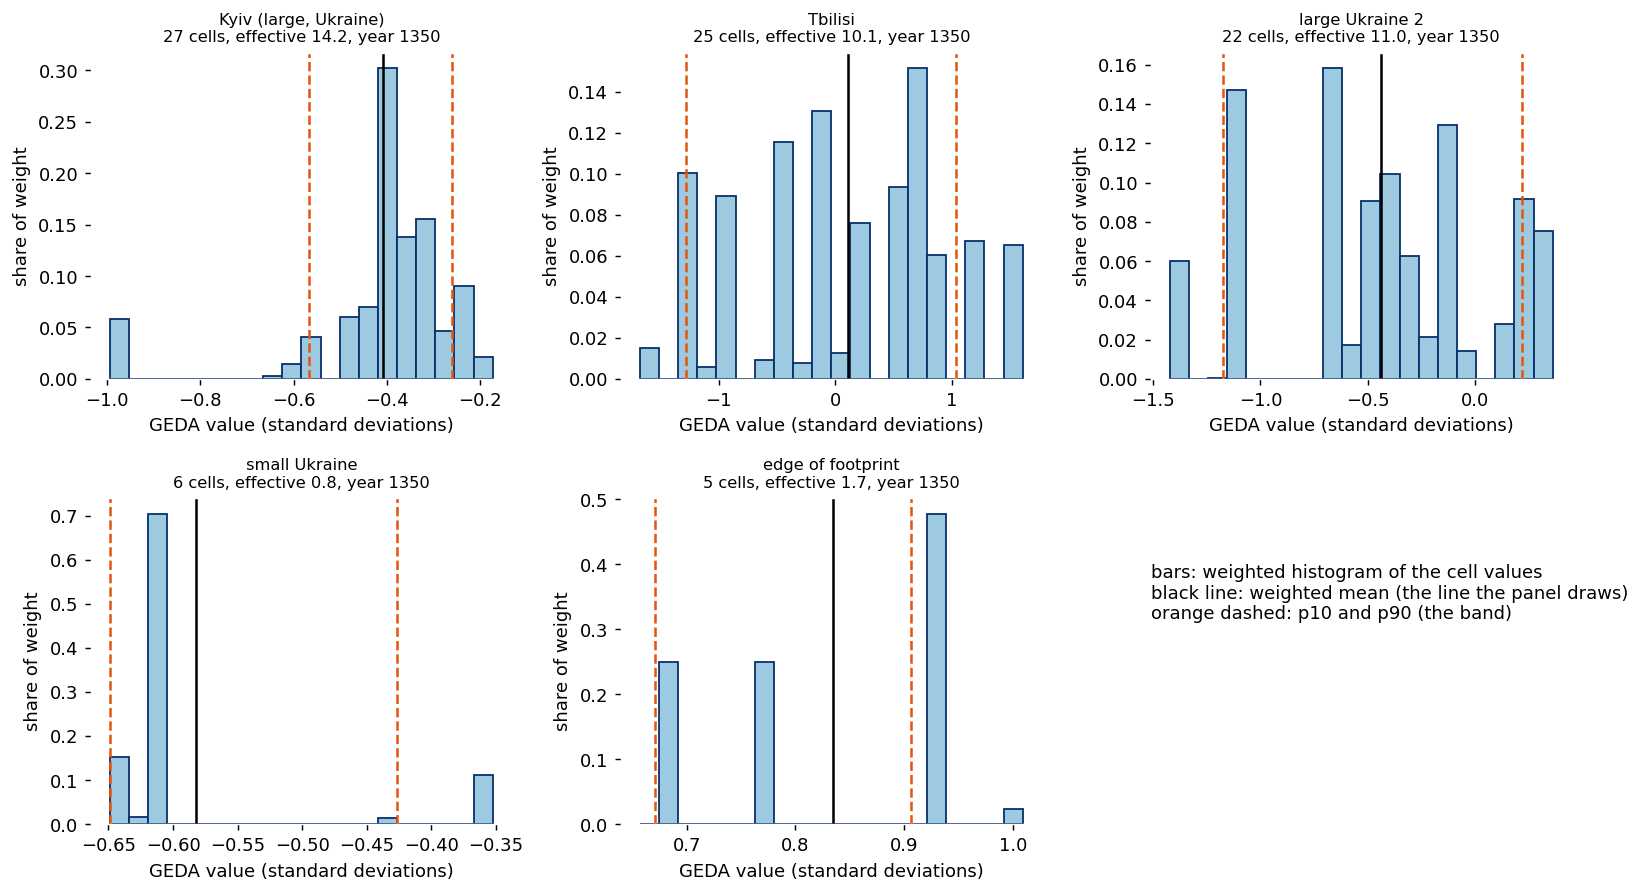

In [13]:
# Cell 8
# Item 6 as a figure: the panel's year histogram for each test basin in 1350. Bars: the weighted histogram of the cell
# values (engine._weighted_histogram); black line: the weighted mean (the panel's line); orange dashed: p10 and p90.
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display

SAMPLE = 1350
outpath = OUT / 'wo02_item6_distribution.png'
print('drawing figure...')
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
fig.patch.set_facecolor('white')
axes = axes.ravel()
for ax, (n, blk) in zip(axes, BLK.items()):
    ax.set_facecolor('white')
    col = blk['M'][:, SAMPLE - blk['years'][0]]
    h = engine._weighted_histogram(col, blk['frac'], unit_type='geda_cell')
    edges, w = np.array(h['bins']), np.array(h['weights'])
    ax.bar(edges[:-1], w, width=np.diff(edges), align='edge', color='#9ecae1', edgecolor='#08306b')
    for key, colr, ls in (('p10', '#e6550d', '--'), ('p90', '#e6550d', '--'), ('mean', 'black', '-')):
        ax.axvline(h[key], color=colr, ls=ls, lw=1.4)
    ax.set_title(f"{n}\n{len(col)} cells, effective {blk['w_eff']:.1f}, year {SAMPLE}", fontsize=9, color='black')
    ax.set_xlabel('GEDA value (standard deviations)', color='black')
    ax.set_ylabel('share of weight', color='black')
    ax.tick_params(colors='black')
axes[5].axis('off')
axes[5].text(0.0, 0.8, 'bars: weighted histogram of the cell values\nblack line: weighted mean (the line the panel draws)\n'
                       'orange dashed: p10 and p90 (the band)', color='black', fontsize=10, va='top')
fig.tight_layout()
fig.savefig(outpath, facecolor='white', dpi=130, bbox_inches='tight')
plt.close(fig)
display(IPImage(str(outpath)))


In [12]:
# Cell 9
# Items 7 and 8: the summary line. For each test basin, the weighted-mean series 1000-2020 as the LMR block computes it,
# how its spread compares with the cells' (item 7), and the alternative: the same series re-standardised against its own
# 1000-2020 record, mean 0 and SD 1 (item 8). Averaging cells that move together only partly lowers the spread; the mean
# correlation between the basin's cells is shown because it is what sets the ratio.
SER = {n: geda_rows(blk) for n, blk in BLK.items()}
rows = []
for n, blk in BLK.items():
    s = SER[n].value.values
    cell_sd = blk['M'].std(axis=1)                                  # each cell's SD over 1000-2020 (1 by construction)
    wsd = float(np.dot(blk['weight'], cell_sd))
    corr = np.corrcoef(blk['M']) if len(cell_sd) > 1 else np.array([[1.0]])
    off = corr[~np.eye(len(corr), dtype=bool)] if len(cell_sd) > 1 else np.array([np.nan])
    rows.append({'basin': n, 'cells': len(cell_sd), 'w_eff': round(blk['w_eff'], 2), 'sd_of_series': round(s.std(), 3),
                 'cells_sd(weighted)': round(wsd, 3), 'ratio': round(s.std() / wsd, 3), 'times_to_unit_sd': round(1 / s.std(), 2),
                 'mean_cell_corr': round(float(np.nanmean(off)), 3),
                 'median_p10_p90_width': round(float((SER[n].p90 - SER[n].p10).median()), 3),
                 'years_flagged_low_res': f"{SER[n].low_res.mean():.0%}"})
YEARS = (1350, 1500, 1816, 2010)
alt = []
for n in BLK:
    s = SER[n].set_index('year').value
    z = (s - s.mean()) / s.std()
    alt.append({'basin': n, **{f'{y} raw': round(float(s[y]), 3) for y in YEARS}, **{f'{y} restd': round(float(z[y]), 3) for y in YEARS}})
print('\n'.join(['Item 7, the weighted-mean line against the cells (1000-2020):', pd.DataFrame(rows).to_string(index=False),
                 'Item 8, selected years: the raw weighted mean and the re-standardised value (z = (x - mean) / SD of the basin series):',
                 pd.DataFrame(alt).to_string(index=False)]))


Item 7, the weighted-mean line against the cells (1000-2020):
                basin  cells  w_eff  sd_of_series  cells_sd(weighted)  ratio  times_to_unit_sd  mean_cell_corr  median_p10_p90_width years_flagged_low_res
Kyiv (large, Ukraine)     27  14.25         0.951                 1.0  0.951              1.05           0.882                 0.605                    0%
              Tbilisi     25  10.08         0.854                 1.0  0.854              1.17           0.640                 1.177                    0%
      large Ukraine 2     22  11.04         0.948                 1.0  0.948              1.05           0.863                 0.717                    0%
        small Ukraine      6   0.82         0.993                 1.0  0.993              1.01           0.970                 0.192                  100%
    edge of footprint      5   1.70         0.982                 1.0  0.982              1.02           0.918                 0.349                  100%
Item 8, 

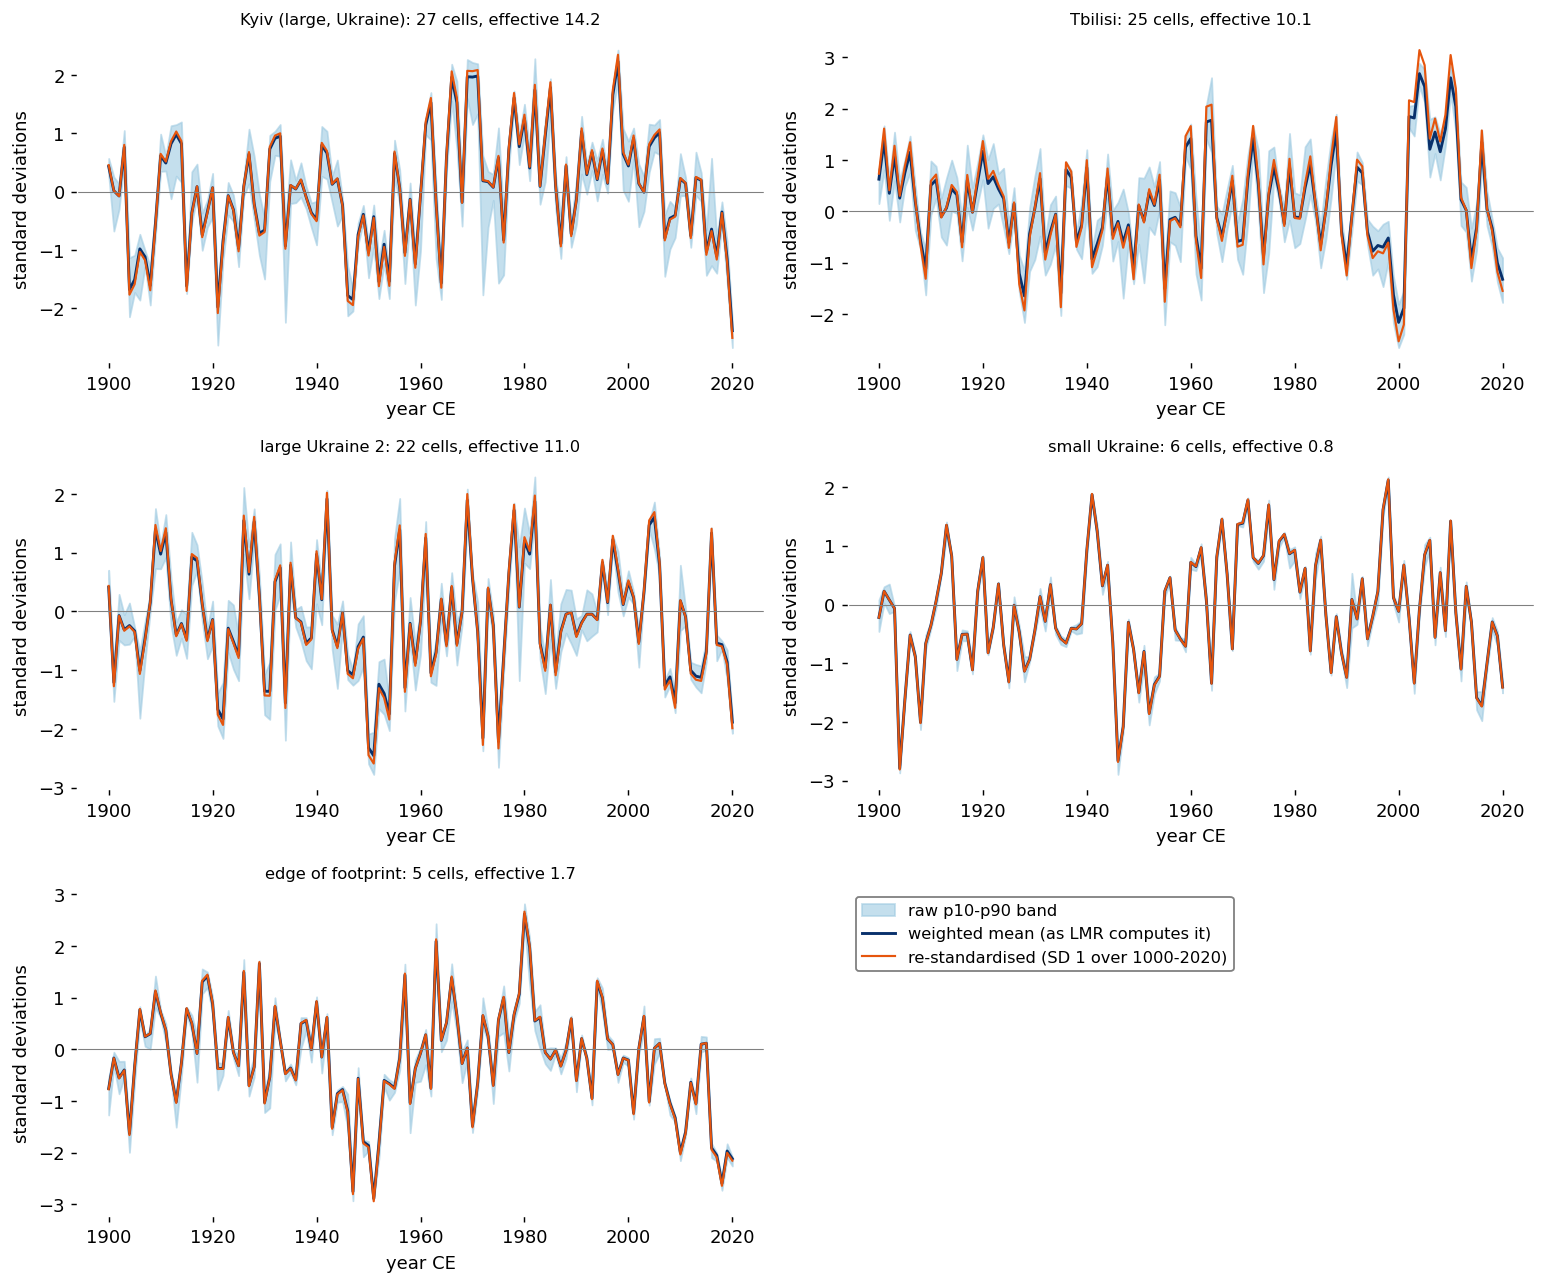

In [14]:
# Cell 10
# Items 7 and 8 as a figure: for each test basin, the weighted-mean line (navy) and the re-standardised line (orange),
# 1900-2020, with the raw p10-p90 band shaded. Needs SER from Cell 9.
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display

outpath = OUT / 'wo02_item7_8_lines.png'
print('drawing figure...')
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
fig.patch.set_facecolor('white')
axes = axes.ravel()
for ax, n in zip(axes, BLK):
    ax.set_facecolor('white')
    d = SER[n]
    z = (d.value - d.value.mean()) / d.value.std()
    m = d.year >= 1900
    ax.fill_between(d.year[m], d.p10[m], d.p90[m], color='#9ecae1', alpha=0.6, label='raw p10-p90 band')
    ax.plot(d.year[m], d.value[m], color='#08306b', lw=1.6, label='weighted mean (as LMR computes it)')
    ax.plot(d.year[m], z[m], color='#e6550d', lw=1.2, label='re-standardised (SD 1 over 1000-2020)')
    ax.axhline(0, color='grey', lw=0.6)
    ax.set_title(f"{n}: {len(BLK[n]['frac'])} cells, effective {BLK[n]['w_eff']:.1f}", fontsize=9, color='black')
    ax.set_xlabel('year CE', color='black')
    ax.set_ylabel('standard deviations', color='black')
    ax.tick_params(colors='black')
axes[5].axis('off')
h_, l_ = axes[0].get_legend_handles_labels()
leg = axes[5].legend(h_, l_, loc='upper left', fontsize=9, framealpha=1, facecolor='white', edgecolor='grey')
for t in leg.get_texts():
    t.set_color('black')
fig.tight_layout()
fig.savefig(outpath, facecolor='white', dpi=130, bbox_inches='tight')
plt.close(fig)
display(IPImage(str(outpath)))


In [15]:
# Cell 11
# Item 9: small and edge cases beyond the two test basins. A basin with one GEDA cell overlapping, one with two, one
# covered below 10% by GEDA cells, and one entirely outside the footprint (central Africa): what the GEDA block returns,
# and the values for 1350. Uses cov (Cell 5) and geda_block, geda_rows (Cell 6).
def pick(df):
    return basin_by_id(int(df.sort_values('area_km2', ascending=False).hybas_id.iloc[0]))

CASES = {
    'one cell': pick(cov[(cov.n_cells == 1) & (cov.coverage > 0.99)]),
    'two cells': pick(cov[(cov.n_cells == 2) & (cov.coverage > 0.99)]),
    'coverage below 10%': pick(cov[(cov.coverage < 0.1) & (cov.area_km2 >= 5000)]),
    'outside the footprint': basin_by_point(-5.0, 25.0),
}
rows = []
for name, b in CASES.items():
    blk = geda_block(b['wkt'])
    base = {'case': name, 'hybas_id': b['hybas_id'], 'area_km2': round(b['area_km2'])}
    if blk is None:
        rows.append({**base, 'cells': 0, 'result': 'no cells overlap: no rows returned (absent, not zero)'})
        continue
    r = geda_rows(blk).set_index('year').loc[1350]
    rows.append({**base, 'cells': len(blk['frac']), 'centres': blk['n_centres'], 'w_eff': round(blk['w_eff'], 3),
                 'coverage': round(blk['coverage'], 3), 'value_1350': round(r.value, 3), 'p10': round(r.p10, 3),
                 'p90': round(r.p90, 3), 'min': round(r['min'], 3), 'max': round(r['max'], 3), 'low_resolution': bool(r.low_res)})
print('Item 9, what the GEDA block returns:\n' + pd.DataFrame(rows).fillna('').to_string(index=False))


Item 9, what the GEDA block returns:
                 case   hybas_id  area_km2  cells centres  w_eff coverage value_1350    p10    p90    min    max low_resolution                                                result
             one cell 4060029310       986      1     1.0  0.324      1.0     -0.865 -0.865 -0.865 -0.865 -0.865           True                                                      
            two cells 2060693490      1754      2     1.0  0.717      1.0       1.02  0.996  1.032  0.996   1.04           True                                                      
   coverage below 10% 1060264990     37000      3     0.0  0.886    0.067      1.226 -0.146  1.633 -0.146   1.77           True                                                      
outside the footprint 1061132570     55432      0                                                                               no cells overlap: no rows returned (absent, not zero)


In [16]:
# Cell 12
# Item 10: year ranges, following LMR's handling (a span that partly overlaps the data is clipped; one entirely outside
# returns nothing), compared with what the engine returns for LMR on the same Kyiv basin; and timings. The engine call also
# builds the HYDE and eVolv2k rows, so its time is an upper bound for LMR alone. Uses kyiv, tbilisi, geda_block, geda_rows.
import time
b = kyiv
SPANS = [(1300, 1400), (1350, 1350), (900, 1100), (990, 1010), (2000, 2100), (2015, 2025), (500, 600), (2030, 2040)]
rows = []
for a, z in SPANS:
    blk = geda_block(b['wkt'], a, z)
    lm = [r for r in engine.aggregate_band_t(b['lat'], b['lon'], 0, a, z, conn, geom_wkt=b['wkt']) if r['variable'] == 'lmr_pdsi']
    rows.append({'span asked': f'{a}-{z}',
                 'GEDA rows': 0 if blk is None else len(blk['years']),
                 'GEDA years': '-' if blk is None else f"{blk['years'][0]}-{blk['years'][-1]}",
                 'LMR rows': len(lm), 'LMR years': '-' if not lm else f"{lm[0]['year']}-{lm[-1]['year']}"})

def timed(fn, reps=3):
    best = 1e9
    for _ in range(reps):
        t = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t)
    return best

trow = []
for name, bb in (('Kyiv', kyiv), ('Tbilisi', tbilisi)):
    blk = geda_block(bb['wkt'])
    trow.append({'basin': name,
                 'GEDA block SQL, 1000-2020 (s)': round(timed(lambda: geda_block(bb['wkt'])), 2),
                 'GEDA per-year rows, 1000-2020 (s)': round(timed(lambda: geda_rows(blk), reps=1), 2),
                 'GEDA block + rows, 1300-1400 (s)': round(timed(lambda: geda_rows(geda_block(bb['wkt'], 1300, 1400))), 2),
                 'engine Band T (LMR+HYDE+eVolv2k), 1300-1400 (s)': round(timed(lambda: engine.aggregate_band_t(bb['lat'], bb['lon'], 0, 1300, 1400, conn, geom_wkt=bb['wkt'])), 2)})
print('\n'.join(['Item 10, spans (Kyiv basin):', pd.DataFrame(rows).to_string(index=False),
                 'timings, best of three (the per-year rows once):', pd.DataFrame(trow).to_string(index=False)]))


Item 10, spans (Kyiv basin):
span asked  GEDA rows GEDA years  LMR rows LMR years
 1300-1400        101  1300-1400       101 1300-1400
 1350-1350          1  1350-1350         1 1350-1350
  900-1100        101  1000-1100       201  900-1100
  990-1010         11  1000-1010        21  990-1010
 2000-2100         21  2000-2020         0         -
 2015-2025          6  2015-2020         0         -
   500-600          0          -       101   500-600
 2030-2040          0          -         0         -
timings, best of three (the per-year rows once):
  basin  GEDA block SQL, 1000-2020 (s)  GEDA per-year rows, 1000-2020 (s)  GEDA block + rows, 1300-1400 (s)  engine Band T (LMR+HYDE+eVolv2k), 1300-1400 (s)
   Kyiv                           0.01                               0.03                              0.01                                             0.08
Tbilisi                           0.01                               0.03                              0.01                        

In [17]:
# Cell 13
# Item 11 (text): the Kyiv basin, 1300-1400: the GEDA and LMR PDSI series as the two panels would show them. LMR from
# engine.aggregate_band_t (the signature's own path), GEDA from the block in Cell 6. The figure is Cell 14.
blk_k = geda_block(kyiv['wkt'], 1300, 1400)
gk = geda_rows(blk_k).set_index('year')
lm = [r for r in engine.aggregate_band_t(kyiv['lat'], kyiv['lon'], 0, 1300, 1400, conn, geom_wkt=kyiv['wkt']) if r['variable'] == 'lmr_pdsi']
lk = pd.DataFrame([{'year': r['year'], 'value': r['representative_raw'], 'p10': r['detail']['distribution']['p10'],
                    'p90': r['detail']['distribution']['p90'], 'n_units': r['n_units'],
                    'low_res': r['detail']['distribution']['low_resolution']} for r in lm]).set_index('year')
both = pd.DataFrame({'GEDA': gk.value, 'GEDA_p10': gk.p10, 'GEDA_p90': gk.p90, 'LMR': lk.value, 'LMR_p10': lk.p10, 'LMR_p90': lk.p90})
L = [f"Kyiv basin {kyiv['hybas_id']}, 1300-1400: GEDA {len(blk_k['frac'])} cells (effective {blk_k['w_eff']:.2f}), LMR {int(lk.n_units.iloc[0])} cells; "
     f"LMR low_resolution in {lk.low_res.mean():.0%} of years, GEDA in {gk.low_res.mean():.0%}",
     'every tenth year (GEDA is a standard score, LMR an anomaly in PDSI units; the scales differ):',
     both.iloc[::10].round(3).to_string(),
     f"SD over the span: GEDA {gk.value.std():.3f}, LMR {lk.value.std():.3f}; Pearson r between the two lines: {both.GEDA.corr(both.LMR):.3f}; "
     f"median p10-p90 width: GEDA {(gk.p90 - gk.p10).median():.3f}, LMR {(lk.p90 - lk.p10).median():.3f}"]
print('\n'.join(L))


Kyiv basin 2060448220, 1300-1400: GEDA 27 cells (effective 14.25), LMR 3 cells; LMR low_resolution in 100% of years, GEDA in 0%
every tenth year (GEDA is a standard score, LMR an anomaly in PDSI units; the scales differ):
       GEDA  GEDA_p10  GEDA_p90    LMR  LMR_p10  LMR_p90
year                                                    
1300 -1.195    -1.349    -1.123  0.218    0.203    0.225
1310 -0.232    -0.682    -0.063 -0.068   -0.114   -0.043
1320 -0.189    -0.390     0.005  0.476    0.459    0.487
1330  1.118    -0.177     1.511  0.158    0.097    0.196
1340 -0.299    -0.611    -0.170  0.093    0.074    0.103
1350 -0.408    -0.567    -0.261  0.688    0.614    0.731
1360 -0.980    -1.189    -0.800  0.754    0.745    0.758
1370  0.852     0.695     1.020  0.109    0.041    0.149
1380  1.379     1.189     1.566 -0.418   -0.422   -0.416
1390  0.512    -0.775     0.828 -0.456   -0.466   -0.451
1400  1.555     1.274     2.248 -0.003   -0.023    0.008
SD over the span: GEDA 1.036, LMR 0.3

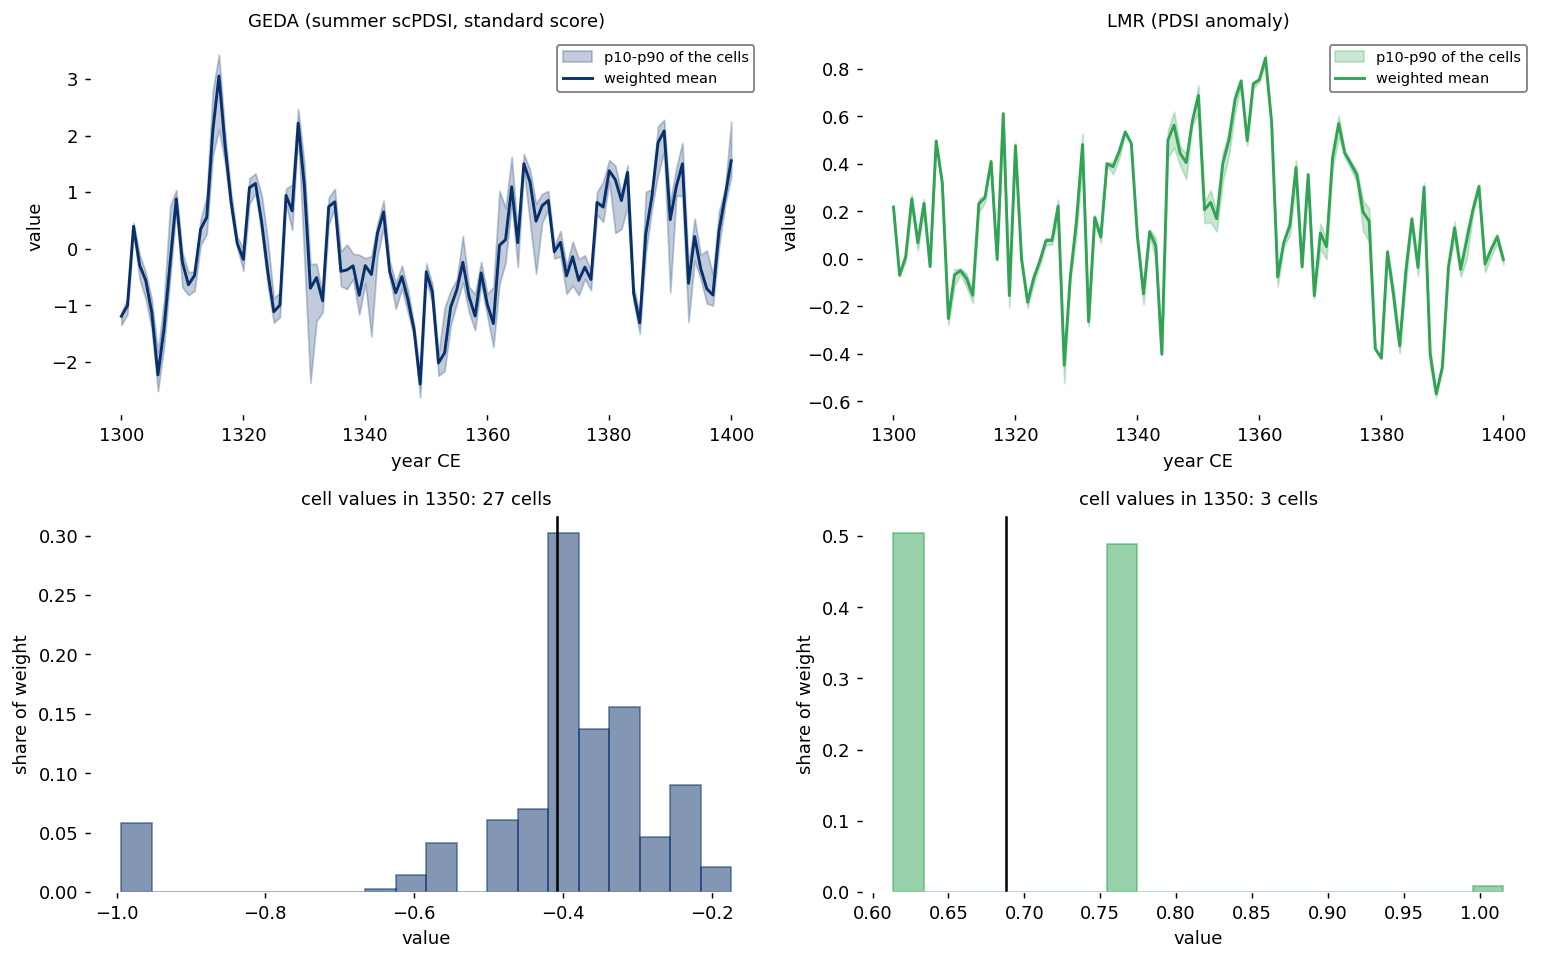

In [19]:
# Cell 14
# Item 11 as a figure: GEDA and LMR PDSI panels for the Kyiv basin, 1300-1400. Top: the line with its p10-p90 band. Bottom:
# the histogram of cell values for the middle year (1350). Needs gk, lk, blk_k, lm from Cell 13.
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display

outpath = OUT / 'wo02_item11_geda_vs_lmr.png'
print('drawing figure...')
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
fig.patch.set_facecolor('white')
YR = 1350
col = blk_k['M'][:, YR - blk_k['years'][0]]
hg = engine._weighted_histogram(col, blk_k['frac'], unit_type='geda_cell')
hl = [r for r in lm if r['year'] == YR][0]['detail']['distribution']
panels = [('GEDA (summer scPDSI, standard score)', gk, hg, '#08306b'), ('LMR (PDSI anomaly)', lk, hl, '#31a354')]
for j, (title, d, h, colr) in enumerate(panels):
    ax = axes[0, j]
    ax.set_facecolor('white')
    ax.fill_between(d.index, d.p10, d.p90, color=colr, alpha=0.25, label='p10-p90 of the cells')
    ax.plot(d.index, d.value, color=colr, lw=1.6, label='weighted mean')
    ax.set_title(title, fontsize=10, color='black')
    ax.set_xlabel('year CE', color='black')
    ax.set_ylabel('value', color='black')
    ax.tick_params(colors='black')
    leg = ax.legend(loc='upper right', fontsize=8, framealpha=1, facecolor='white', edgecolor='grey')
    for t in leg.get_texts():
        t.set_color('black')
    ax2 = axes[1, j]
    ax2.set_facecolor('white')
    edges, w = np.array(h['bins']), np.array(h['weights'])
    ax2.bar(edges[:-1], w, width=np.diff(edges), align='edge', color=colr, alpha=0.5, edgecolor=colr)
    ax2.axvline(h['mean'], color='black', lw=1.4)
    ax2.set_title(f"cell values in {YR}: {h['n_units']} cells", fontsize=10, color='black')
    ax2.set_xlabel('value', color='black')
    ax2.set_ylabel('share of weight', color='black')
    ax2.tick_params(colors='black')
fig.tight_layout()
fig.savefig(outpath, facecolor='white', dpi=130, bbox_inches='tight')
plt.close(fig)
display(IPImage(str(outpath)))


In [18]:
# Cell 15
# Item 12: the 1990 check. For the L6 basins that lie at least half inside Ukraine: the difference between the mean of
# 1960-1989 and the mean of 1990-2020 (the last pair), against the differences between every other pair of adjacent 30-year
# windows since 1000 (1000-1029, 1030-1059, ... 1960-1989, then 1990-2020). Also (not in the WO; Cell 10's figure suggests it):
# the spread between cells, the median p10-p90 width, before and from 1990. rank 1 = the largest absolute difference.
ukr_sql = """SELECT b.hybas_id, ST_Area(ST_Intersection(b.geom, u.geom)::geography) / ST_Area(b.geom::geography) AS frac
             FROM public.basin06 b, (SELECT geom FROM gaz.admin0 WHERE adm0_a3 = 'UKR') u WHERE ST_Intersects(b.geom, u.geom)"""
ub = pd.read_sql(ukr_sql, conn)
ub = ub[ub.frac >= 0.5]
WINS = [(a, a + 29) for a in range(1000, 1990, 30)] + [(1990, 2020)]
rows, area_series = [], []
for hid in ub.hybas_id.astype(int):
    b = basin_by_id(hid)
    blk = geda_block(b['wkt'])
    s = blk['weight'] @ blk['M']
    area_series.append(s)
    yrs = blk['years']
    means = np.array([s[(yrs >= a) & (yrs <= z)].mean() for a, z in WINS])
    d = np.diff(means)                                       # d[-1] is 1960-1989 -> 1990-2020
    others = np.abs(d[:-1])
    width = geda_rows(blk).eval('p90 - p10')
    rows.append({'hybas_id': hid, 'area_km2': round(b['area_km2']), 'cells': len(blk['frac']), 'diff_1990': d[-1],
                 'median_abs_other': np.median(others), 'max_abs_other': others.max(),
                 'rank_of_1990': int((np.abs(d) > abs(d[-1])).sum()) + 1,
                 'width_to_1989': float(width[yrs < 1990].median()), 'width_from_1990': float(width[yrs >= 1990].median())})
res = pd.DataFrame(rows)
res['width_ratio'] = res.width_from_1990 / res.width_to_1989
am = np.mean(area_series, axis=0)
am_means = np.array([am[(yrs >= a) & (yrs <= z)].mean() for a, z in WINS])
am_d = np.diff(am_means)
L = [f'basins at least half inside Ukraine: {len(res)}; windows: {len(WINS)} ({len(WINS) - 1} adjacent pairs)',
     'difference of means, 1990-2020 minus 1960-1989, across basins (min, median, max): '
     f'{res.diff_1990.min():.3f}, {res.diff_1990.median():.3f}, {res.diff_1990.max():.3f}',
     f'the other adjacent pairs, median absolute difference across basins: {res.median_abs_other.median():.3f}; the largest of them: {res.max_abs_other.max():.3f}',
     'rank of the 1990 pair among all adjacent pairs by absolute difference (1 = largest), basins per rank band: '
     f'1-3: {int((res.rank_of_1990 <= 3).sum())}, 4-10: {int(((res.rank_of_1990 > 3) & (res.rank_of_1990 <= 10)).sum())}, '
     f'11 or more: {int((res.rank_of_1990 > 10).sum())}',
     f'Ukraine-wide average series (these basins, equal weight): 1990 pair difference {am_d[-1]:.3f}; median absolute difference of the other pairs '
     f'{np.median(np.abs(am_d[:-1])):.3f}; rank {int((np.abs(am_d) > abs(am_d[-1])).sum()) + 1} of {len(am_d)}',
     f'between-cell spread (median p10-p90 width): to 1989 vs from 1990, ratio across basins (10th, median, 90th percentile): '
     f'{res.width_ratio.quantile(0.1):.2f}, {res.width_ratio.median():.2f}, {res.width_ratio.quantile(0.9):.2f}',
     'the ten largest basins:',
     res.sort_values('area_km2', ascending=False).head(10).round(3).to_string(index=False)]
print('\n'.join(L))


basins at least half inside Ukraine: 68; windows: 34 (33 adjacent pairs)
difference of means, 1990-2020 minus 1960-1989, across basins (min, median, max): -0.683, -0.456, 0.081
the other adjacent pairs, median absolute difference across basins: 0.281; the largest of them: 1.296
rank of the 1990 pair among all adjacent pairs by absolute difference (1 = largest), basins per rank band: 1-3: 1, 4-10: 18, 11 or more: 49
Ukraine-wide average series (these basins, equal weight): 1990 pair difference -0.396; median absolute difference of the other pairs 0.178; rank 11 of 33
between-cell spread (median p10-p90 width): to 1989 vs from 1990, ratio across basins (10th, median, 90th percentile): 0.55, 0.86, 1.29
the ten largest basins:
  hybas_id  area_km2  cells  diff_1990  median_abs_other  max_abs_other  rank_of_1990  width_to_1989  width_from_1990  width_ratio
2060448220     28495     27     -0.528             0.295          0.968            10          0.605            0.603        0.997
20604